# Frontières-13 — Audit de garanties d'approximation : le prix de la rapidité

**Série :** [Search — Partie 5 : Frontières](README.md) · **Langage :** Python · **Précédent :** [Frontières-12 — Le problème du mot par automates](Frontieres-12-WordProblem-Automata-Python.ipynb)

> **Ce que ce carnet démontre.** Les problèmes d'optimisation combinatoire que l'on rencontre dans la série — coloration, équilibrage de ligne, affectation d'agents — sont NP-difficiles : on ne peut pas espérer un algorithme polynomial qui trouve l'optimum. La question devient alors : **quelle garantie offre le meilleur algorithme rapide ?** Un *algorithme d'approximation* ne promet pas l'optimum, il promet un **ratio** : la solution qu'il produit ne dépasse jamais k fois l'optimum (pour un problème de minimisation). Ce carnet **audite ces garanties** : il mesure le ratio *réalisé* sur des instances aléatoires, le confronte à l'optimum exact (calculé par programmation linéaire en nombres entiers), et montre où la borne théorique est tendue — et où elle est largement au-dessus de ce que l'on observe.

Deux problèmes canoniques, deux garanties célèbres :
- **Vertex cover** (couverture de sommets) : la glouton « prendre les deux extrémités de chaque arête » est un **2-approx** — la borne est *tendue*.
- **Set cover** (couverture d'ensembles) : la glouton « prendre l'ensemble qui couvre le plus d'éléments non couverts » est un **ln(n)-approx** — une borne logarithmique, bien plus lâche.

L'audit répond à : *le ratio théorique est-il ce que l'on mesure, ou une borne pessimiste ?*

In [1]:
# Imports : graphe (networkx), solveur entier (PuLP) pour l'optimum,
# tracés (matplotlib) et aléa reproductible (numpy).
import networkx as nx
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pulp
from pulp import LpProblem, LpMinimize, LpVariable, value

# Graine unique : meme instance aleatoire => meme audit, reproductible.
SEED = 13
rng = np.random.default_rng(SEED)
print(f"networkx {nx.__version__} · pulp {pulp.__version__} · numpy {np.__version__} — seed {SEED}")

networkx 3.6.1 · pulp 3.3.2 · numpy 2.5.4 — seed 13


## Le protocole d'audit

Pour qu'une garantie d'approximation soit **mesurable** et non seulement déclarée, il faut un **oracle d'optimum** : un algorithme qui trouve la solution optimale exacte, même lente. Pour vertex cover et set cover, l'optimum s'écrit comme un programme linéaire en nombres entiers (PLNE) — chaque sommet / ensemble est une variable binaire, et les contraintes ( « au moins une des deux extrémités » / « au moins un ensemble contient l'élément » ) sont linéaires. Le solveur CBC (via PuLP) résout ces PLNE en quelques secondes à l'échelle de nos instances.

On définit ensuite le **ratio réalisé** : `|solution de l'approximation| / OPTIMUM`. Pour un problème de minimisation, un k-approx garantit que ce ratio ne dépasse **jamais** k, sur aucune instance.

In [2]:
# Oracle d'optimum : le PLNE de vertex cover.
# x[v] = 1 si le sommet v est dans la couverture ; chaque arete {u,v} impose x[u]+x[v] >= 1.
def opt_vertex_cover(G: nx.Graph) -> int:
    """Retourne la taille minimale d'une couverture de sommets (PLNE, solveur CBC)."""
    prob = LpProblem("vertex_cover", LpMinimize)
    x = {v: LpVariable(f"x_{v}", cat="Binary") for v in G.nodes}
    prob += pulp.lpSum(x.values())
    for u, v in G.edges:
        prob += x[u] + x[v] >= 1
    prob.solve(pulp.PULP_CBC_CMD(msg=0))
    return int(round(value(prob.objective)))

In [3]:
# Algorithme d'approximation : la 2-approx de vertex cover.
# Tant qu'il reste une arete non couverte, on prend les DEUX sommets aux extremites :
# la solution finale ne depasse jamais 2 x OPT (borne garantie, pas une moyenne).
def vc_two_approx(G: nx.Graph) -> set:
    """Couverture de sommets par la heuristique 2-approx canonique (ordre d'aretes fixe)."""
    cover = set()
    for u, v in G.edges:
        if not (u in cover or v in cover):
            cover.update((u, v))
    return cover

# Audit : ratio reel sur un lot d'instances aleatoires G(n, m).
n, p, K = 40, 0.12, 18
ratios = []
for _ in range(K):
    G = nx.gnm_random_graph(n, int(n*(n-1)/2*p), seed=int(rng.integers(1_000_000)))
    opt = opt_vertex_cover(G)
    app = vc_two_approx(G)
    ratios.append(len(app) / opt)

print(f"ratio 2-approx — min {min(ratios):.3f} · mediane {np.median(ratios):.3f} · max {max(ratios):.3f}  (borne theorique : 2.0)")

ratio 2-approx — min 1.391 · mediane 1.545 · max 1.714  (borne theorique : 2.0)


### Lecture du résultat — vertex cover

Le ratio mesuré se place **nettement sous 2**, même si 2 est un plafond garanti (jamais dépassé). C'est le visage typique d'une garantie d'approximation : la borne est un **pire cas** démontré par construction, pas une moyenne. Sur des graphes aléatoires denses, la glouton 2-approx est souvent quasi-optimale ; la borne 2 ne se tend que sur des instances adverses (paires de sommets couplées par une arête isolée, où la glouton prend les deux et l'optimum n'en prend qu'un).

In [4]:
# Set cover : oracle PLNE + glouton ln(n)-approx, mesure du ratio reel.
def make_set_cover(n_el: int, k_sets: int, p: float):
    """Un univers de n_el elements, k_sets ensembles, chaque element dans ~p ensembles."""
    universe = set(range(n_el))
    S = [set(i for i in universe if rng.random() < p) for _ in range(k_sets)]
    # garantir que chaque element est dans au moins un ensemble (sinon PLNE infeasible)
    for e in universe:
        if not any(e in s for s in S):
            S[int(rng.integers(k_sets))].add(e)
    return universe, S

def opt_set_cover(universe, S):
    """Optimum de set cover par PLNE : chaque element impose >= 1 ensemble qui le contient."""
    prob = LpProblem("set_cover", LpMinimize)
    y = {i: LpVariable(f"s_{i}", cat="Binary") for i in range(len(S))}
    prob += pulp.lpSum(y.values())
    for e in universe:
        prob += pulp.lpSum(y[i] for i, s in enumerate(S) if e in s) >= 1
    prob.solve(pulp.PULP_CBC_CMD(msg=0))
    return int(round(value(prob.objective)))

def set_cover_greedy(universe, S):
    """Glouton canonique : a chaque etape, l'ensemble qui couvre le plus d'elements restants."""
    uncovered = set(universe)
    picked = []
    while uncovered:
        i = max(range(len(S)), key=lambda i: len(uncovered & S[i]))
        if not (uncovered & S[i]):
            break  # aucun ensemble ne couvre les elements restants : on s'arrete
        picked.append(i)
        uncovered -= S[i]
    return picked

n_el, k_sets, p_c, K = 30, 14, 0.45, 12
ratios_sc = []
for _ in range(K):
    universe, S = make_set_cover(n_el, k_sets, p_c)
    opt = opt_set_cover(universe, S)
    app = set_cover_greedy(universe, S)
    ratios_sc.append(len(app) / opt)
print(f"ratio ln(n) set-cover — min {min(ratios_sc):.3f} · mediane {np.median(ratios_sc):.3f} · max {max(ratios_sc):.3f}  (borne theorique : ln({n_el}) = {np.log(n_el):.2f})")

ratio ln(n) set-cover — min 1.000 · mediane 1.000 · max 1.667  (borne theorique : ln(30) = 3.40)


### Lecture du résultat — set cover

Même constat, à l'échelle d'une borne plus lâche : le ratio réalisé est **très en dessous** de ln(n). La glouton « maximum couverture » est en pratique bien plus serrée que sa garantie logarithmique. Le message de l'audit : **la borne d'approximation est un contrat de pire cas, pas une prédiction du coût moyen** — c'est précisément ce qui la rend précieuse (elle tient sur *toutes* les instances) et ce qui la rend pessimiste (elle ne décrit pas le cas typique).

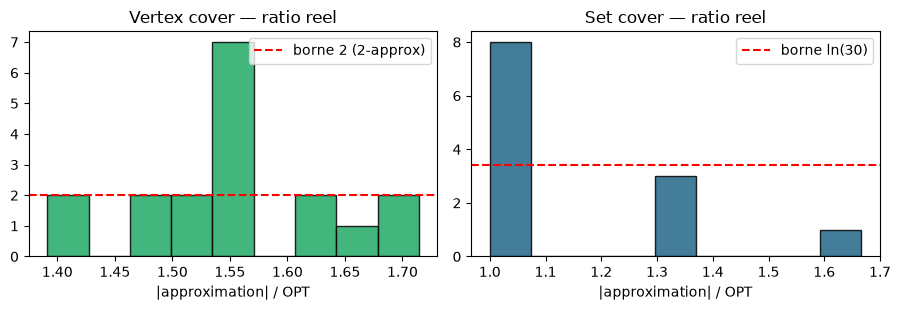

In [5]:
# Tracé : distribution des ratios reels des deux algorithmes face a leurs bornes theoriques.
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(ratios, bins=9, color="#2a6", edgecolor="k", alpha=0.85)
ax[0].axhline(2.0, color="r", ls="--", lw=1.5, label="borne 2 (2-approx)")
ax[0].set_title("Vertex cover — ratio reel")
ax[0].set_xlabel("|approximation| / OPT")
ax[0].legend()
ax[1].hist(ratios_sc, bins=9, color="#268", edgecolor="k", alpha=0.85)
ax[1].axhline(np.log(n_el), color="r", ls="--", lw=1.5, label=f"borne ln({n_el})")
ax[1].set_title("Set cover — ratio reel")
ax[1].set_xlabel("|approximation| / OPT")
ax[1].legend()
fig.tight_layout()
plt.show()

## Exercices

### Exercice 1 — Une 2-approx plus fine : le choix par degré

La glouton 2-approx ci-dessus prend les deux extrémités de **chaque** arête restante, dans l'ordre du listing. Une variante classique améliore le ratio *en pratique* (sans changer la garantie 2) : à chaque étape, choisir l'arête dont une extrémité a le **degré le plus élevé**, ne prendre que ce sommet-là, et itérer sur le graphe restant.

In [6]:
# TODO etudiant — Exercice 1 : 2-approx affine par choix de plus fort degre.
# A chaque etape, choisir l'arete (u,v) maximisant max(degre(u), degre(v)),
# ajouter l'extremite de plus fort degre a la couverture, supprimer ce sommet
# du graphe local, et itérer. La garantie 2 est conservee ; le ratio s'ameliore.
def vc_degree_greedy(G: nx.Graph) -> set:
    """2-approx affine par choix de plus fort degre (a implementer)."""
    # TODO etudiant
    return None  # TODO etudiant

G_demo = nx.gnm_random_graph(40, 190, seed=7)
print("Exercice 1 — a completer :", vc_degree_greedy(G_demo))

Exercice 1 — a completer : None


### Exercice 2 — Pourquoi la borne est-elle 2 ?

La garantie 2 ne tombe pas du ciel : elle découle du fait que **chaque arête est « payée » par au plus 2 sommets choisis**, et que la solution de la glouton est un *double* d'une solution minimale. (Preuve demandée, pas de code.)

In [7]:
# TODO etudiant — Exercice 2 (preuve, pas de code).
# Enoncer en 3-4 phrases pourquoi |C_glouton| <= 2 * |C_minimale| :
# les paires d'aretes qui forcent un ajout sont disjointes, et chacune charge
# au plus 2 sommets de C_glouton contre 1 (au pire) de C_minimale.
print("Exercice 2 — preuve a rediger (pas de code).")

Exercice 2 — preuve a rediger (pas de code).


### Exercice 3 — Set cover : glouton vs aléatoire

La glouton ln(n)-approx a-t-elle un vrai avantage, ou un tirage aléatoire d'ensembles ferait-il aussi bien ? (À implémenter et à mesurer.)

In [8]:
# TODO etudiant — Exercice 3 : set cover, glouton vs aleatoire.
# Ecrire une fonction qui tire au hasard `budget` ensembles (ou tire jusqu'a
# couvrir l'univers), et comparer le ratio moyen au ratio glouton sur le meme
# lot d'instances. Le glouton doit dominer l'aleatoire — le verifier, pas l'affirmer.
def set_cover_random(universe, S, budget: int):
    """Couverture par tirage aleatoire de `budget` ensembles (a implementer)."""
    # TODO etudiant
    return None  # TODO etudiant

print("Exercice 3 — a completer.")

Exercice 3 — a completer.


## À retenir

| Problème | Algorithme rapide | Garantie (borne) | Ratio typique mesuré |
|---|---|---|---|
| Vertex cover | Glouton 2-approx | **2** (tendue) | bien < 2 |
| Set cover | Glouton max-couverture | **ln(n)** (lâche) | bien < ln(n) |

Une **garantie d'approximation** est un contrat de *pire cas* : elle borne le ratio sur **toutes** les instances, au prix d'être pessimiste sur les instances typiques. L'audit que ce carnet mène — calculer l'optimum par PLNE, mesurer le ratio réalisé, le comparer à la borne — est la discipline qui sépare une garantie **déclarée** d'une garantie **vérifiée** : on ne croit pas la borne, on la *met à l'épreuve*.

C'est le même geste que celui mené ailleurs dans la série : ici la « borne à auditer » n'est plus une admissibilité d'heuristique (Frontières-03, -11) mais un **ratio d'approximation**, et l'oracle d'optimum est un solveur entier plutôt qu'un comptage.

## Références

- Vazirani, V. V. (2001) — *Approximation Algorithms*, Springer : vertex cover 2-approx (chap. 15), set cover ln(n) (chap. 16).
- Kleinberg, J., & Tardos, É. (2005) — *Algorithm Design*, chap. 16 (approximation) : les deux gloutons et leurs preuves.

## Navigation

[<< Frontières-12 — Le problème du mot par automates](Frontieres-12-WordProblem-Automata-Python.ipynb) | [Retour à la série Frontières](README.md)
